# Práctica 2 — Introducción al aprendizaje supervisado

**Machine Learning · Máster Universitario en Inteligencia Artificial · curso 2026/2027**

Grupo: *4* · Integrantes: *Carlos Chapman Peña*, *Miguel Ángel Gordillo Masero*, *María Xiaolan Ríos Díaz*, *Pablo Sola Díaz*

---

Cuaderno **de partida**. La primera celda de código fija vuestro grupo y vuestra semilla y carga
los datos; la última escribe los dos ficheros que subís a Kaggle. **Entre medias, el cuaderno es
vuestro**: los títulos de los ejercicios solo marcan el orden. La interpretación va en celdas
Markdown, no en comentarios de Python.

## 0. Entorno, semilla y datos

Declarad `GRUPO` y `SEMILLA` antes de nada. **Toda la aleatoriedad del cuaderno sale de
`SEMILLA`**: las particiones de la validación, los desempates y cualquier `random_state`.

In [1]:
# --- Práctica 2: grupo, semilla, entorno y datos --------------------------------
GRUPO = 4        # vuestro número de grupo (entero)
SEMILLA = 67      # vuestra semilla (entero): toda la aleatoriedad sale de aquí

import os, sys, platform
import numpy as np, pandas as pd, matplotlib, sklearn, scipy
import matplotlib.pyplot as plt

assert isinstance(GRUPO, int) and isinstance(SEMILLA, int), "Declarad GRUPO y SEMILLA (enteros) antes de seguir."

DATOS = os.path.join("..", "Datos")                  # relativa a este cuaderno
sys.path.insert(0, os.path.join("..", "Codigo"))     # código proporcionado por el curso
from oner import OneRClassifier, OneRRegressor
from comprobar_estimador import comprobar_estimador

ciber_train = pd.read_csv(os.path.join(DATOS, "ciber_train.csv"))
ciber_test = pd.read_csv(os.path.join(DATOS, "ciber_test.csv"))
latencia_train = pd.read_csv(os.path.join(DATOS, "latencia_train.csv"))
latencia_test = pd.read_csv(os.path.join(DATOS, "latencia_test.csv"))

X_CIBER = [c for c in ciber_test.columns if c != "id"]          # características de ciber
X_LATENCIA = [c for c in latencia_test.columns if c != "id"]    # características de latencia

print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("GRUPO       ", GRUPO, "· SEMILLA", SEMILLA)
print("ciber       ", ciber_train.shape, ciber_test.shape)
print("latencia    ", latencia_train.shape, latencia_test.shape)

python       3.14.8
numpy        2.5.3
pandas       3.0.6
scikit-learn 1.9.1
GRUPO        4 · SEMILLA 67
ciber        (5000, 13) (5000, 12)
latencia     (5000, 11) (3000, 10)


## Ejercicio 1. Cómo vais a medir

*(TODO)*

### 1(a) Datos de ciber_train

In [2]:
ciber_train.info()
#Contar valores nulos
nulos_ciber = ciber_train.isnull().sum()
print(nulos_ciber)


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            5000 non-null   str    
 1   proto         5000 non-null   str    
 2   service       5000 non-null   str    
 3   conn_state    5000 non-null   str    
 4   duration      5000 non-null   float64
 5   src_bytes     5000 non-null   int64  
 6   dst_bytes     5000 non-null   int64  
 7   missed_bytes  5000 non-null   int64  
 8   src_pkts      5000 non-null   int64  
 9   src_ip_bytes  5000 non-null   int64  
 10  dst_pkts      5000 non-null   int64  
 11  dst_ip_bytes  5000 non-null   int64  
 12  attack_type   5000 non-null   str    
dtypes: float64(1), int64(7), str(5)
memory usage: 607.8 KB
id              0
proto           0
service         0
conn_state      0
duration        0
src_bytes       0
dst_bytes       0
missed_bytes    0
src_pkts        0
src_ip_bytes    0
dst_pkts        0
d

### 1(a) Datos de latencia_train

In [3]:
# Información general
latencia_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             5000 non-null   str    
 1   block_size     5000 non-null   int64  
 2   n_jobs         5000 non-null   int64  
 3   iodepth        5000 non-null   int64  
 4   read_fraction  5000 non-null   int64  
 5   load_type      5000 non-null   str    
 6   io_type        5000 non-null   str    
 7   raid           5000 non-null   str    
 8   n_disks        5000 non-null   int64  
 9   device_type    5000 non-null   str    
 10  latency_ns     5000 non-null   float64
dtypes: float64(1), int64(5), str(5)
memory usage: 555.9 KB


Con .info() comprobamos que no hay valores nulos en ninguna de las características del conjunto de datos y podemos ver el tipo de dato de cada una.

In [4]:
display(latencia_train.describe())

nominales = ['load_type', 'io_type', 'raid', 'device_type']
for col in nominales:
    print(latencia_train[col].value_counts())
    print("\n")

,block_size,n_jobs,iodepth,read_fraction,n_disks,latency_ns
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,208.576000,16.88100,16.934000,40.684000,17.994000,2.407129e+07
std,301.354501,15.54494,10.060412,36.357097,6.719598,9.319971e+07
min,4.000000,1.00000,1.000000,0.000000,3.000000,1.143315e+05
25%,16.000000,6.00000,8.000000,0.000000,12.000000,6.099692e+05
50%,64.000000,12.00000,15.000000,35.000000,20.000000,1.240523e+06
75%,256.000000,20.00000,27.000000,75.000000,24.000000,8.127825e+06
max,1024.000000,64.00000,32.000000,100.000000,24.000000,1.262194e+09


load_type
random        3270
sequential    1730
Name: count, dtype: int64


io_type
write    2980
read     2020
Name: count, dtype: int64


raid
4+1    2180
2+2     600
4+2     565
8+2     560
1+1     560
2+1     535
Name: count, dtype: int64


device_type
nvme    4210
hdd      790
Name: count, dtype: int64




Con .describe() mostramos un resumen estadístico de las características, que incluye la media, la desviación típica, los cuartiles y los valores mínimos y máximos. A partir de estos últimos, podemos observar que las características tienen escalas bastante diferentes. Por ejemplo, `block_size` toma valores entre 4 y 1024, mientras que los valores de `latency_ns` son mucho más elevados, llegando hasta 1.262.194.000. Otras variables, como `n_jobs` e `iodepth`, tienen rangos más reducidos. Estas diferencias de escala deben tenerse en cuenta durante el preprocesamiento, porque puede ser necesario aplicar técnicas de normalización o estandarización antes de entrenar el modelo.

Por otro lado, las variables categóricas muestran distribuciones desiguales: en `load_type` predomina random (3.270) frente a sequential (1.730); en `io_type` también hay más registros de write (2.980) que de read (2.020); en `raid` destaca 4+1 como la configuración más frecuente (2.180), mientras que las demás tienen frecuencias similares, con valores entre 535 y 600 registros; y en `device_type` domina claramente nvme (4.210) sobre hdd (790).

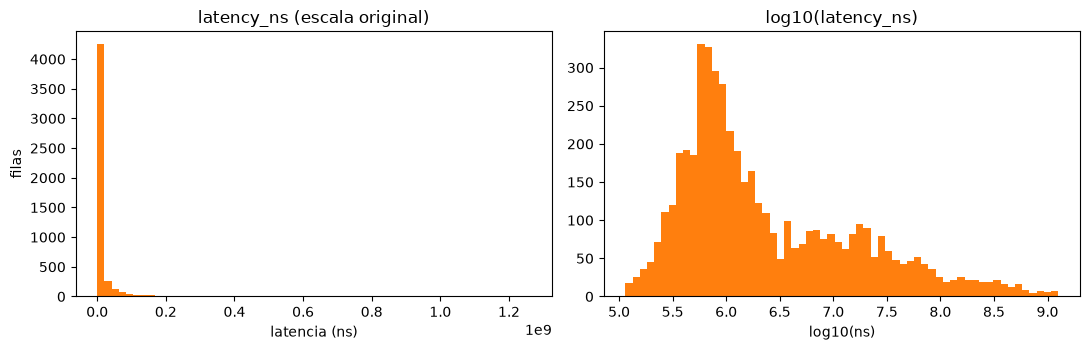

In [5]:
# Distribución de la variable objetivo (latencia_ns) en train
y = latencia_train["latency_ns"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(y, bins=60, color="C1"); ax[0].set_title("latency_ns (escala original)")
ax[0].set_xlabel("latencia (ns)"); ax[0].set_ylabel("filas")
ax[1].hist(np.log10(y), bins=60, color="C1"); ax[1].set_title("log10(latency_ns)")
ax[1].set_xlabel("log10(ns)")
plt.tight_layout(); plt.show()

En las gráficas podemos observar la distribución de la variable objetivo (`latency_ns`) tanto en su escala original como después de aplicar la transformación logarítmica `log10`.

En la escala original, la distribución es muy asimétrica hacia la derecha, ya que la mayoría de las observaciones tienen valores bajos, mientras que existen algunos valores de latencia muy altos que alargan la distribución.

Al aplicar la transformación logarítmica, reducimos esta asimetría y visualizamos mejor la distribución de los datos. De esta forma, podemos observar con más claridad las diferencias entre las latencias y conocer mejor el comportamiento de la variable antes de utilizarla en el modelo.

In [6]:
# Cuánto varían las cinco ejecuciones de una misma configuración

# Se definen las columnas que representan la "configuración" (todas menos 'id' y 'latency_ns')
configuracion = [c for c in latencia_train.columns if c not in ['id', 'latency_ns']]

grupos_lat = latencia_train.groupby(configuracion)["latency_ns"]
ratio_max_min = grupos_lat.max() / grupos_lat.min()
std_log10 = grupos_lat.apply(lambda s: np.log10(s).std(ddof=1))

resumen_var = pd.DataFrame({
    "ratio_max_min": ratio_max_min,
    "std_log10_ns": std_log10,
})
print("Resumen de variabilidad entre las 5 ejecuciones (1.000 configuraciones):")
display(
    resumen_var.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T[[
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "90%",
        "max",
    ]]
)

# Ejemplo de una configuración y sus 5 latencias distintas
ejecuciones = grupos_lat.size()
ejemplo = ejecuciones[ejecuciones == 5].index[0]
ejemplo = (latencia_train[configuracion] == ejemplo).all(axis=1)
ejemplo = latencia_train[ejemplo][['block_size', 'n_jobs', 'iodepth', 'read_fraction', 'load_type', 'io_type', 'raid', 'n_disks', 'device_type', 'latency_ns']]
print("\nEjemplo de las 5 ejecuciones para una misma configuración:")
display(ejemplo)
latencias = ejemplo['latency_ns']

Resumen de variabilidad entre las 5 ejecuciones (1.000 configuraciones):


,count,mean,std,min,25%,50%,75%,90%,max
ratio_max_min,1000.0,1.287067,1.139653,1.000245,1.021795,1.068416,1.223296,1.572391,26.24800
std_log10_ns,1000.0,0.030703,0.053001,0.000044,0.003833,0.011891,0.035911,0.080515,0.62397



Ejemplo de las 5 ejecuciones para una misma configuración:


,block_size,n_jobs,iodepth,read_fraction,load_type,io_type,raid,n_disks,device_type,latency_ns
408,4,2,11,23,random,read,4+1,24,nvme,121127.5
543,4,2,11,23,random,read,4+1,24,nvme,117519.0
3819,4,2,11,23,random,read,4+1,24,nvme,116699.0
4349,4,2,11,23,random,read,4+1,24,nvme,119568.5
4960,4,2,11,23,random,read,4+1,24,nvme,118525.0


La primera tabla muestra cuánto varía la latencia (`latency_ns`) entre las 5 repeticiones de cada una de las 1.000 configuraciones únicas. Para ello, se utilizan dos métricas:
* **`ratio_max_min`**: indica cuántas veces mayor es la latencia máxima respecto a la mínima de una misma configuración. Un valor cercano a 1 significa que las ejecuciones han tenido resultados muy similares, mientras que valores más altos indican una mayor diferencia entre ellas.
* **`std_log10_ns`**: mide la desviación típica de `log10(latency_ns)` dentro de cada configuración. Permite analizar la variabilidad teniendo en cuenta que las diferencias de latencia pueden ser multiplicativas y no siempre siguen una distribución simétrica.

### Resumen de variabilidad

En la mayoría de las configuraciones se observa una variabilidad bastante baja entre las cinco repeticiones. La mediana (`50%`) de `ratio_max_min` es 1.068, lo que significa que, en un caso típico, la ejecución más lenta tarda aproximadamente un 6,8 % más que la más rápida. Además, en el `75 %` de las configuraciones el ratio no supera 1.223. La mediana de `std_log10_ns` también es baja (0.0119), lo que confirma que, por lo general, las distintas ejecuciones ofrecen resultados bastante similares.

Sin embargo, hay algunas configuraciones que presentan diferencias mucho más importantes entre repeticiones. Esto se refleja en que la media de `ratio_max_min` (1.287) es superior a su mediana (1.068), lo que indica que existen algunos valores extremos que elevan el promedio. Aunque la mayoría de los casos son bastante estables, el percentil 90 alcanza 1.572 y el valor máximo llega a 26.248. Esto significa que, en alguna configuración concreta, la ejecución más lenta ha tardado más de 26 veces que la más rápida.

Estos resultados muestran que una misma configuración no siempre produce exactamente la misma latencia, ya que existen variaciones entre sus distintas ejecuciones, probablemente debido a la existencia de ruido.

### Ejemplo

La segunda tabla muestra un ejemplo concreto de la variabilidad de la latencia en las cinco ejecuciones de una configuración. En este caso, se puede ver que no varía demasiado.

**¿Qué hace difícil este problema?**

La predicción de la latencia es difícil debido a diferentes cosas:

- **Asimetría de su distribución:** La variable objetivo tiene un rango de valores muy amplio (desde aproximadamente $10^5$ hasta $10^9$ ns) y una distribución muy sesgada. Esto es importante porque el $MAE_{\log}$ calcula el error absoluto medio sobre el logaritmo decimal de la latencia:
   $$MAE_{\log} = \frac{1}{n} \sum_{i=1}^{n} \vert{}\log_{10} y_i - \log_{10} \hat{y}_i\vert{}$$
   A diferencia del $MAE$, que mide las diferencias absolutas en las unidades originales y hace que los errores en valores más altos tengan mayor peso, el $MAE_{\log}$ tiene en cuenta los errores relativos. De esta forma, evita que las latencias más elevadas condicionen tanto el resultado de la evaluación. Esto significa que un error multiplicativo del mismo tamaño (por ejemplo, desviarse por un factor de 1.26) recibe la misma penalización, independientemente de si se produce en latencias de microsegundos o de milisegundos.

- **La variabilidad entre ejecuciones de una misma configuración:** Como hemos visto en la tabla anterior, los resultados de las cinco repeticiones de una misma configuración varían un poco debido al ruido, lo que planteará la decisión de si entrenar el modelo con todas las filas o calcular un valor medio que represente cada configuración en el Ejercicio 3.

- **Que puedan existir relaciones no lineales e interacciones entre las características:** El rendimiento del almacenamiento depende de varios factores que se influyen entre sí, como el tamaño de bloque, la profundidad de cola, el número de hilos y el tipo de RAID. Por ello, es necesario utilizar modelos que puedan detectar cómo afectan sus distintas combinaciones al rendimiento.

- **Hay variables numéricas y categóricas:** Como el conjunto de datos combina ambos tipos de variables, es necesario realizar un preprocesamiento adecuado antes de entrenar el modelo. Para ello, se deberán transformar las variables categóricas mediante técnicas de codificación y escalar las numéricas para evitar que unas tengan más peso que otras. Esto es muy importante en KNN porque utiliza distancias para determinar qué configuraciones son más similares entre sí.

### 1(b) Protocolos de latencia_train

**Protocolo de validación: latencia**

Esquemas de validación que vamos a probar.  Con el mismo modelo y métricas probaremos los siguientes métodos: 

- 1º Validación cruzada aleatoria por filas, con 5 particiones del conjunto de entrenamiento.
- 2º Validación cruzada por grupos, con 5 particiones,donde cada grupo son las diferentes configuraciónes (definidas por sus respectivas 9 características). Esto se hace para que las cinco ejecuciones de una configuración caigan siempre en la misma partición. Además, dentro de cada grupo dividiremos en intervalos según la latencia media de cada configuración, para que todas las particiones cubran el rango completo de latencias.

La métrica que usaremos para medir la calidad del modelo será MAElog, que es la de la competición. Entrenaremos con log10(latencia) y tras esto desharemos el logaritmo con 10^ŷ (ŷ serán las predicciones que devuelva el modelo), para que sean positivas. Informaremos de la media y de la dispersión entre particiones, usando las mismas particiones para todos los candidatos.

Elección en base a los posibles resultados de la comparación:

Al validar sin agrupar por grupos de configuración vemos un MAElog más alto que el de la validación cuando se agrupan, siendo más optimista. Esto es debido a lo siguiente: 

De cada grupo de configuracion (denotemos a un grupo de ejemplo como G1), tenemos 5 ejecuciones distintas. Si en el grupo de validación de G1 caen solo dos ejecuciones (G1_1 y G1_2), otras tres caerán para el grupo de validación (G1_3 G1_4 G1_5). Entonces, cuando el modelo reciba por ejemplo la tercera ejecución de G1 (G1_3) , verá que está a distancia cero de G1_2 y G1_1, por lo que predecirá G1_3 en función de las latencias de G1_1 y G1_2. Esto hará que el modelo se ajuste demasiado al conjunto de entrenamiento (haya sobreajuste), y cuando introduzca datos nuevos del conjunto test, no prediga bien, ya que se ha ajustado demasiado al conjunto de entrenamiento. 

Por lo que seleccionaremos aunque tenga peor métrica la validación por grupos con 5 particiones. Cada partición deja unas 200 configuraciones en validación (unas 1000 filas) y unas 800 para entrenar.


Aparte de este método, para ver en que intervalos de latencias falla más el modelo, dividimos la latencia real en intervalos (cortes en log10 fijados [a priori / con el entrenamiento de cada ronda]) y calculamos el MAElog en cada uno, junto con la precisión y la exhaustividad. Este análisis no interviene en la elección de modelos. 


In [16]:

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, StratifiedGroupKFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Variables que vamos a utilizar
nominales = ["load_type", "io_type", "raid", "device_type"]
numericas = ["block_size", "n_jobs", "iodepth", "read_fraction", "n_disks"]

lat = latencia_train.copy()
lat["ylog"] = np.log10(lat["latency_ns"])

# Identificamos las configuraciones
lat["grupo"] = grupos_lat.ngroup()

# Dividimos las configuraciones en 5 grupos según su latencia media
media_config = lat.groupby("grupo")["ylog"].mean() #agrupo en grupos de config y extraigo su media
bins = pd.qcut(media_config, 5, labels=False)  #Dividimos las 1000 config en 5 grupos segun su media 
lat["bin"] = lat["grupo"].map(bins) #Asignamos a cada fila el grupo de latencia al que pertenece su configuración.

X_lat = lat[configuracion]
y_lat = lat["ylog"]

# Creamos las particiones para los dos protocolos
n_part = 5

filas = list(KFold(n_splits=n_part, shuffle=True, random_state=SEMILLA).split(X_lat))

grupos = list(
    StratifiedGroupKFold(n_splits=n_part, shuffle=True, random_state=SEMILLA).split(X_lat, lat["bin"], lat["grupo"]))


# Función para crear el modelo KNN con su preprocesamiento
def crear_knn(k):
    preprocesamiento = ColumnTransformer([("numericas", StandardScaler(), numericas),
        ("nominales", OneHotEncoder(handle_unknown="ignore"), nominales)])
    modelo = Pipeline([ ("preprocesamiento", preprocesamiento),
        ("knn", KNeighborsRegressor(n_neighbors=k)) ])
    return modelo

# Calculamos el MAE en escala logarítmica para cada partición
def calcular_mae(k, particiones):
    resultados = cross_val_score(crear_knn(k), X_lat,y_lat,cv=particiones,scoring="neg_mean_absolute_error" )
    return -resultados


# Comparamos los dos protocolos para distintos valores de K
resultados = []

for k in [1,2,3,4,5,6,7,8,9,10]:
    mae_filas = calcular_mae(k, filas)
    mae_grupos = calcular_mae(k, grupos)
    resultados.append({ "K": k, "MAE_filas": mae_filas.mean(),"std_filas": mae_filas.std(),
                       "MAE_grupos": mae_grupos.mean(),"std_grupos": mae_grupos.std() })

comparacion_protocolos = pd.DataFrame(resultados)
comparacion_protocolos


,K,MAE_filas,std_filas,MAE_grupos,std_grupos
0,1,0.033623,0.001514,0.261648,0.024276
1,2,0.033632,0.001255,0.259390,0.023873
2,3,0.042267,0.002612,0.259302,0.023477
3,4,0.065154,0.004823,0.259188,0.023220
4,5,0.095508,0.005934,0.259573,0.023877
5,6,0.118582,0.006368,0.236358,0.021106
6,7,0.134249,0.006035,0.224628,0.017704
7,8,0.143182,0.005748,0.219418,0.014915
8,9,0.148083,0.005477,0.217374,0.012836
9,10,0.151294,0.005788,0.217189,0.011705


## Apartado 1 (c) latencia 

## Posibles fugas de información y cómo evitarlas

Durante el desarrollo del protocolo hemos identificado seis posibles situaciones en las que podría producirse una fuga de información entre los datos de entrenamiento y los de validación.

**1. Las cinco ejecuciones de cada configuración.**

El problema de las cinco ejecuciones diferentes de cada configuración. Este problema causaría sobreajuste del modelo al conjunto de entrenamiento, y está descrito en el 1(b). Para evitarlo, utilizamos una validación cruzada por grupos, para que las cinco ejecuciones de una misma configuración siempre permanezcan juntas en validación o entrenamiento.

**2. El preprocesamiento de los datos.**

Al preparar los datos, es posible que se necesite aprender información de los propios datos( como las medias y desviaciones de cada tipo de configuración). Si hacemos esto antes de separar los datos en entrenamiento y validación en cada iteración, estaríamos utilizando indirectamente información de validación durante el entrenamiento. Por ejemplo, si queremos estandarizar datos, y hacemos validación cruzada. Separamos primero en entrenamiento y validación, y luego al conjunto de entrenamiento de cada iteración le calculamos la media y la desviación para restarle la media y dividirlo por la desviación y asi estandarizár. Si calculásemos eso a partir del conjunto de validación y entrenamiento, obtendríamos información del conjunto de validación, del cual el modelo no debería saber nada. 


**3. Los intervalos de latencia.**

También hay que tener cuidado con los intervalos que se utilizan para agrupar los valores de latencia. Como se calculan a partir de la variable que queremos predecir, no debemos permitir que esa información llegue al modelo como entrada.

Los utilizamos únicamente para organizar las particiones o analizar los resultados. Además, sus límites se establecen previamente o se calculan utilizando solo los datos de entrenamiento de cada partición.

**4. La elección de los mejores hiperparámetros.**

Cuando comparamos distintas configuraciones del modelo, utilizamos el mismo sistema de validación y la misma métrica para todas ellas. Sin embargo, si elegimos hiperparámetros para los cuales el modelo obtiene el menor error y después presentamos ese mismo resultado como si fuera una evaluación independiente, podemos estar sobreestimando su rendimiento.

Para tener esto en cuenta, analizamos también las diferencias entre las distintas particiones y evitamos dar demasiada importancia a pequeñas mejoras. 



## Ejercicio 2. Modelos de referencia: ZeroR y OneR

*(TODO)*

## Ejercicio 3. KNN de scikit-learn

*(TODO)*

## Ejercicio 4. Vuestro KNN clasificador y la competición de ciberseguridad

*(TODO)*

## Ejercicio 5. Vuestro KNN regresor y la competición de latencia

*(TODO)*

## Envío final

**Esta debe ser la última celda del cuaderno.** Entrena vuestros dos modelos finales, que llevan
dentro vuestro KNN propio, con **todo** el conjunto de entrenamiento y escribe los dos ficheros.
Si en latencia entrenáis con un resumen de las cinco ejecuciones de cada configuración, calculadlo
aquí, en `X_final_latencia` e `y_final_latencia`. Lo que subáis a Kaggle como envío final tiene que
ser exactamente lo que escribe esta celda: el profesor volverá a ejecutar el cuaderno y lo
comprobará. No cambiéis los nombres de los modelos ni de los ficheros.

In [ ]:
# --- ENVÍO FINAL: esta celda es la ÚLTIMA del cuaderno ---------------------------
modelo_final_ciber = None   # TODO: vuestro Pipeline con vuestro KNN clasificador
modelo_final_latencia = None   # TODO: vuestro Pipeline con vuestro KNN regresor

# Datos de entrenamiento de los modelos finales: todo el entrenamiento.
X_final_ciber, y_final_ciber = ciber_train[X_CIBER], ciber_train["attack_type"]
X_final_latencia, y_final_latencia = latencia_train[X_LATENCIA], latencia_train["latency_ns"]

modelo_final_ciber.fit(X_final_ciber, y_final_ciber)
modelo_final_latencia.fit(X_final_latencia, y_final_latencia)

envio_ciber = pd.DataFrame({"id": ciber_test["id"],
                            "attack_type": modelo_final_ciber.predict(ciber_test[X_CIBER])})
envio_latencia = pd.DataFrame({"id": latencia_test["id"],
                               "latency_ns": modelo_final_latencia.predict(latencia_test[X_LATENCIA])})
assert (envio_latencia["latency_ns"] > 0).all(), "la latencia predicha tiene que ser positiva"
envio_ciber.to_csv("envio_ciber.csv", index=False)
envio_latencia.to_csv("envio_latencia.csv", index=False)
print("envio_ciber.csv   ", envio_ciber.shape)
print("envio_latencia.csv", envio_latencia.shape)